# **Project Name**    - Paisabazaar Banking Fraud Analysis – Exploratory Data Analysis and Credit Score Classification

##### **Project Type**    - EDA / Classification
##### **Contribution**    - Individual
##### **Team Member 1 -** - N/A
##### **Team Member 2 -** - N/A
##### **Team Member 3 -** - N/A
##### **Team Member 4 -** - N/A

# **Project Summary -**

Write the summary here within 500-600 words.

The Paisabazaar Banking Fraud Analysis project was completed as part of the Labmentix AI/ML Internship. The project focuses on exploratory data analysis (EDA) and credit score classification using customer financial information and credit-related behavioural attributes. The primary objective is to understand patterns in the dataset, investigate relationships between financial indicators and credit score categories, and develop a machine-learning classification workflow.

The dataset contains approximately 100,000 records and 28 columns, including features such as age, annual income, monthly in-hand salary, number of bank accounts, number of credit cards, outstanding debt, credit utilisation ratio, credit mix, payment delays, and credit history age. The target variable, Credit_Score, contains three categories: Good, Standard, and Poor.

The project begins with data loading and preliminary inspection using Python and Pandas. The dataset's dimensions, column names, data types, summary statistics, duplicate records, and missing values are examined to understand its structure and quality. Data cleaning focuses on identifying missing or inconsistent values, handling categorical variations, and investigating unusual observations. These steps help prepare the dataset for reliable analysis and modelling.

Exploratory data analysis is performed using multiple visualisation techniques, including count plots, histograms, box plots, bar plots, correlation heatmaps, and pair plots. These visualisations help examine the distribution of credit score categories, understand numerical feature distributions, identify potential outliers, and explore relationships between financial attributes and credit scores. Correlation analysis is used to investigate relationships among numerical variables, while comparisons across credit score categories help identify patterns that may be relevant to creditworthiness assessment.

The notebook also includes three statistical hypothesis-testing exercises. These investigate whether payment-delay distributions differ across credit score categories, whether annual-income distributions differ across those categories, and whether credit mix is associated with credit score. Appropriate statistical tests are used to evaluate the hypotheses and interpret the resulting p-values. The analysis recognises that statistical association does not necessarily imply causation.

As an extension beyond exploratory analysis, a machine-learning workflow is developed to classify credit scores. The process includes separating input features from the target variable, splitting the data into training and testing sets, and preparing numerical and categorical features through a preprocessing pipeline. Missing numerical values are imputed using the median, categorical missing values are handled using the most frequent category, and categorical features are encoded for model training. The preprocessing pipeline helps apply consistent transformations while reducing the risk of data leakage.

Three classification algorithms are explored: Logistic Regression, Random Forest, and Extra Trees. Their performance is evaluated using metrics such as accuracy, precision, recall, F1-score, macro F1-score, and the confusion matrix. Hyperparameter search is also performed to investigate alternative model configurations. The selected estimator is saved using Joblib and subsequently reloaded to predict sample test records, providing a basic check of model persistence and inference.

Overall, this project provides practical experience in data exploration, data cleaning, visualisation, statistical testing, feature preprocessing, classification, model evaluation, and model persistence. It also highlights the importance of interpreting results carefully, selecting appropriate evaluation metrics, and validating conclusions against actual outputs. The supplied dataset supports credit score analysis and classification; it does not, by itself, establish a validated transaction-level fraud-detection system.

# **GitHub Link -**

[https://github.com/VermaAgentiX/LabmentiX-Projects](https://github.com/VermaAgentiX/LabmentiX-Projects)

# **Problem Statement**


Financial institutions need to assess customer creditworthiness to support lending decisions and manage credit risk. Financial attributes and payment behaviour can provide useful information for understanding credit score categories.

The problem addressed in this project is to explore a customer financial dataset, identify patterns and relationships among relevant variables, and build a machine-learning model that classifies customers into Good, Standard, or Poor credit score categories. The project also aims to evaluate model performance and document the data-analysis workflow. Although the assigned project title refers to banking fraud analysis, the available target variable is credit score rather than a verified fraud label.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [16]:
# Import Libraries
import warnings, re, string, os, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "Credit_Score"


### Dataset Loading

In [17]:
# Load Dataset
DATA_PATH = Path("dataset-2.csv")
if not DATA_PATH.exists():
    matches = list(Path(".").glob("**/dataset-2.csv"))
    if matches:
        DATA_PATH = matches[0]
    else:
        raise FileNotFoundError("Place dataset-2.csv in the same folder as this notebook or update DATA_PATH.")
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()
print("Loaded:", DATA_PATH.resolve(), "| Shape:", df.shape)
display(df.head())


Loaded: C:\Projects\LabmentiX\dataset-2.csv | Shape: (100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,26.823,265.000,No,49.575,21.465,High_spent_Small_value_payments,312.494,Good
1,5635,3392,2,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,4.000,11.270,4.000,Good,809.980,31.945,266.000,No,49.575,21.465,Low_spent_Large_value_payments,284.629,Good
2,5636,3392,3,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,28.609,267.000,No,49.575,21.465,Low_spent_Medium_value_payments,331.210,Good
3,5637,3392,4,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.000,4.000,6.270,4.000,Good,809.980,31.378,268.000,No,49.575,21.465,Low_spent_Small_value_payments,223.451,Good
4,5638,3392,5,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.000,4.000,11.270,4.000,Good,809.980,24.797,269.000,No,49.575,21.465,High_spent_Medium_value_payments,341.489,Good


### Dataset First View

In [18]:
# Dataset First Look
display(df.head())
display(df.tail())
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,26.823,265.000,No,49.575,21.465,High_spent_Small_value_payments,312.494,Good
1,5635,3392,2,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,4.000,11.270,4.000,Good,809.980,31.945,266.000,No,49.575,21.465,Low_spent_Large_value_payments,284.629,Good
2,5636,3392,3,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,28.609,267.000,No,49.575,21.465,Low_spent_Medium_value_payments,331.210,Good
3,5637,3392,4,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.000,4.000,6.270,4.000,Good,809.980,31.378,268.000,No,49.575,21.465,Low_spent_Small_value_payments,223.451,Good
4,5638,3392,5,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.000,4.000,11.270,4.000,Good,809.980,24.797,269.000,No,49.575,21.465,High_spent_Medium_value_payments,341.489,Good


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.000,"78,735,990.000",Mechanic,"39,628.990","3,359.416",4.000,6.000,7.000,2.000,"Auto Loan, and Student Loan",23.000,7.000,11.500,3.000,Good,502.380,34.664,378.000,No,35.104,24.028,High_spent_Large_value_payments,479.866,Poor
99996,155626,37932,5,Nicks,25.000,"78,735,990.000",Mechanic,"39,628.990","3,359.416",4.000,6.000,7.000,2.000,"Auto Loan, and Student Loan",18.000,7.000,11.500,3.000,Good,502.380,40.566,379.000,No,35.104,24.028,High_spent_Medium_value_payments,496.652,Poor
99997,155627,37932,6,Nicks,25.000,"78,735,990.000",Mechanic,"39,628.990","3,359.416",4.000,6.000,7.000,2.000,"Auto Loan, and Student Loan",27.000,6.000,11.500,3.000,Good,502.380,41.256,380.000,No,35.104,24.028,High_spent_Large_value_payments,516.809,Poor
99998,155628,37932,7,Nicks,25.000,"78,735,990.000",Mechanic,"39,628.990","3,359.416",4.000,6.000,7.000,2.000,"Auto Loan, and Student Loan",20.000,6.000,11.500,3.000,Good,502.380,33.638,381.000,No,35.104,24.028,Low_spent_Large_value_payments,319.165,Standard
99999,155629,37932,8,Nicks,25.000,"78,735,990.000",Mechanic,"39,628.990","3,359.416",4.000,6.000,7.000,2.000,"Auto Loan, and Student Loan",18.000,6.000,11.500,3.000,Good,502.380,34.192,382.000,No,35.104,24.028,High_spent_Medium_value_payments,393.674,Poor


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
75721,119215,13625,2,an Arakalid,30.000,"995,314,669.000",Manager,"43,391.960","3,688.997",1.000,5.000,10.000,0.000,No Data,9.000,6.000,10.720,0.000,Good,"1,468.280",29.112,284.000,No,0.000,47.439,High_spent_Large_value_payments,554.930,Good
80184,125910,34582,1,Matthewz,18.000,"185,998,068.000",Scientist,"14,351.210","1,274.934",8.000,7.000,18.000,6.000,"Mortgage Loan, Personal Loan, Not Specified, S...",18.000,17.000,21.910,9.000,Bad,"4,766.870",39.850,98.000,Yes,61.099,21.201,Low_spent_Small_value_payments,238.314,Poor
19864,35430,8668,1,Tom Miless,41.000,"241,538,475.000",Developer,"130,125.040","10,871.753",5.000,2.000,11.000,2.000,"Mortgage Loan, and Debt Consolidation Loan",3.000,0.000,3.820,3.000,Good,"1,195.050",21.543,191.000,No,204.286,103.432,Low_spent_Small_value_payments,271.757,Good
76699,120681,13011,4,Lisaa,35.000,"204,786,176.000",Manager,"20,107.210","1,631.601",6.000,6.000,32.000,2.000,"Credit-Builder Loan, and Home Equity Loan",15.000,13.000,10.400,11.000,Standard,"2,544.600",32.424,232.000,Yes,27.106,10.917,Low_spent_Small_value_payments,359.234,Poor
92991,145117,44461,8,Masond,27.000,"27,116,852.000",Doctor,"92,186.190","7,487.182",1.000,2.000,12.000,4.000,"Personal Loan, Auto Loan, Not Specified, and P...",1.000,0.000,9.740,4.000,Good,809.010,39.543,249.000,No,185.798,84.281,High_spent_Medium_value_payments,697.401,Good


### Dataset Rows & Columns count

In [19]:
# Dataset Rows & Columns count
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print("Column names:", df.columns.tolist())


Rows: 100,000
Columns: 28
Column names: ['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


### Dataset Information

In [20]:
# Dataset Info
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values

In [21]:
# Dataset Duplicate Value Count
print("Exact duplicate rows:", df.duplicated().sum())
if "Customer_ID" in df.columns:
    print("Unique customers:", df["Customer_ID"].nunique(dropna=True))


Exact duplicate rows: 0
Unique customers: 12500


#### Missing Values/Null Values

In [22]:
# Missing Values/Null Values Count
miss = pd.DataFrame({"missing_count": df.isna().sum(),
                     "missing_percent": (df.isna().mean()*100).round(2)})
display(miss.sort_values("missing_percent", ascending=False))


,missing_count,missing_percent
ID,0,0.000
Customer_ID,0,0.000
Month,0,0.000
Name,0,0.000
Age,0,0.000
SSN,0,0.000
Occupation,0,0.000
Annual_Income,0,0.000
Monthly_Inhand_Salary,0,0.000
Num_Bank_Accounts,0,0.000


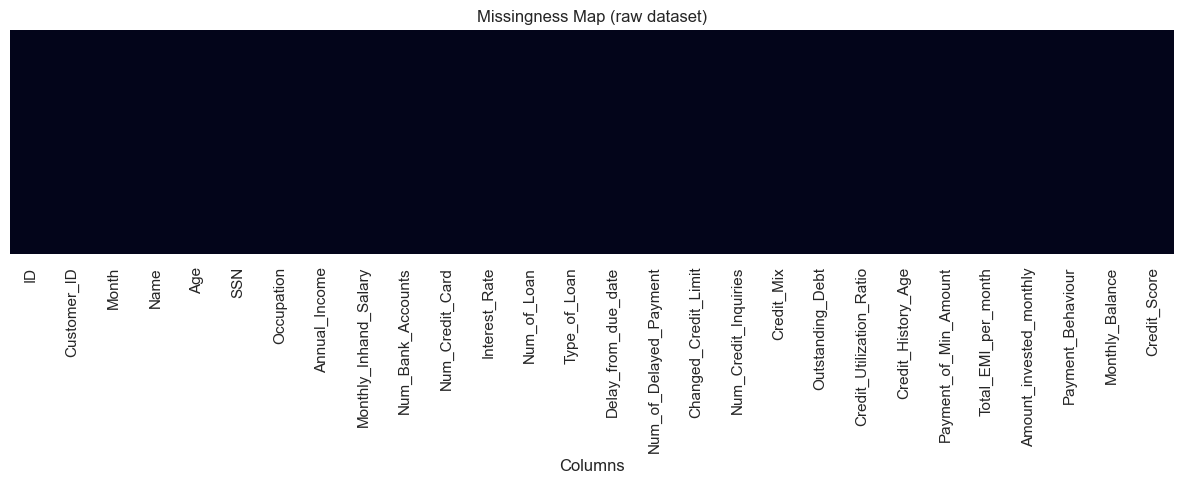

In [23]:
# Visualizing the missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missingness Map (raw dataset)")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()


### What did you know about your dataset?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

## ***2. Understanding Your Variables***

In [24]:
# Dataset Columns
display(pd.DataFrame({"Column": df.columns, "Data type": df.dtypes.astype(str),
                      "Unique values": [df[c].nunique(dropna=True) for c in df.columns]}))


,Column,Data type,Unique values
ID,ID,int64,100000
Customer_ID,Customer_ID,int64,12500
Month,Month,int64,8
Name,Name,object,10128
Age,Age,float64,43
SSN,SSN,float64,12500
Occupation,Occupation,object,15
Annual_Income,Annual_Income,float64,12488
Monthly_Inhand_Salary,Monthly_Inhand_Salary,float64,13241
Num_Bank_Accounts,Num_Bank_Accounts,float64,12


In [25]:
# Dataset Describe
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,"100,000.000",NaN,NaN,NaN,"80,631.500","43,301.487","5,634.000","43,132.750","80,631.500","118,130.250","155,629.000"
Customer_ID,"100,000.000",NaN,NaN,NaN,"25,982.667","14,340.543","1,006.000","13,664.500","25,777.000","38,385.000","50,999.000"
Month,"100,000.000",NaN,NaN,NaN,4.500,2.291,1.000,2.750,4.500,6.250,8.000
Name,100000,10128,Stevex,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"100,000.000",NaN,NaN,NaN,33.316,10.765,14.000,24.000,33.000,42.000,56.000
SSN,"100,000.000",NaN,NaN,NaN,"500,461,680.262","290,826,734.386","81,349.000","245,168,577.250","500,688,611.500","756,002,666.250","999,993,421.000"
Occupation,100000,15,Lawyer,7096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,"100,000.000",NaN,NaN,NaN,"50,505.123","38,299.422","7,005.930","19,342.972","36,999.705","71,683.470","179,987.280"
Monthly_Inhand_Salary,"100,000.000",NaN,NaN,NaN,"4,197.271","3,186.432",303.645,"1,626.594","3,095.905","5,957.715","15,204.633"
Num_Bank_Accounts,"100,000.000",NaN,NaN,NaN,5.369,2.593,0.000,3.000,5.000,7.000,11.000


### Variables Description

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

### Check Unique Values for each variable.

In [26]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"\n{col} — unique values: {df[col].nunique(dropna=True)}")
    display(df[col].value_counts(dropna=False).head(10).to_frame("count"))



ID — unique values: 100000


,count
ID,
5634,1
5635,1
5636,1
5637,1
5638,1
5639,1
5640,1
5641,1
5646,1



Customer_ID — unique values: 12500


,count
Customer_ID,
3392,8
8625,8
11708,8
47249,8
7387,8
38382,8
10314,8
21511,8
16727,8



Month — unique values: 8


...

,count
Payment_Behaviour,
Low_spent_Small_value_payments,28616
High_spent_Medium_value_payments,19738
High_spent_Large_value_payments,14726
Low_spent_Medium_value_payments,14399
High_spent_Small_value_payments,11764
Low_spent_Large_value_payments,10757



Monthly_Balance — unique values: 98494


,count
Monthly_Balance,
236.242,8
"1,183.931",8
396.838,7
803.332,7
281.208,7
235.452,7
"1,040.213",7
224.065,7
36.819,7



Credit_Score — unique values: 3


,count
Credit_Score,
Standard,53174
Poor,28998
Good,17828


## 3. ***Data Wrangling***

### Data Wrangling Code

In [27]:
# Write your code to make your dataset analysis ready.
# Keep df_raw unchanged; clean a working copy.
df = df_raw.copy()

# Normalize whitespace and common placeholder strings.
placeholders = {"", "nan", "none", "null", "na", "n/a", "nm", "_", "__", "___",
                "____", "_____", "______", "_______"}
for col in df.select_dtypes(include=["object", "string"]).columns:
    s = df[col].astype("string").str.strip()
    df[col] = s.mask(s.str.lower().isin(placeholders), pd.NA)

# Parse numeric columns that may contain placeholder text or commas.
numeric_cols = [
    "Month", "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance"
]
for col in numeric_cols:
    if col in df.columns:
        s = df[col].astype("string").str.replace(",", "", regex=False).str.strip()
        df[col] = pd.to_numeric(s, errors="coerce")

# Convert "Credit_History_Age" such as "22 Years and 1 Months" into total months.
if "Credit_History_Age" in df.columns:
    def history_to_months(val):
        if pd.isna(val): return np.nan
        s = str(val).lower()
        yr = re.search(r"(\d+)\s*years?", s)
        mo = re.search(r"(\d+)\s*months?", s)
        if yr or mo:
            return int(yr.group(1) if yr else 0) * 12 + int(mo.group(1) if mo else 0)
        try: return float(s)
        except ValueError: return np.nan
    df["Credit_History_Age"] = df["Credit_History_Age"].map(history_to_months)

# Remove exact duplicate records only.
before = len(df)
df = df.drop_duplicates().copy()
print("Exact duplicates removed:", before - len(df))

# Normalize target labels and categorical text.
if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} is missing.")
df[TARGET] = df[TARGET].astype("string").str.strip().str.title()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Negative values are invalid for these non-negative fields; mark them missing.
nonnegative = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
               "Num_Credit_Card", "Interest_Rate", "Num_of_Loan",
               "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Outstanding_Debt",
               "Total_EMI_per_month", "Amount_invested_monthly"]
for col in nonnegative:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

print("Cleaned shape:", df.shape)
display(df.head())


Exact duplicates removed: 0
Cleaned shape: (100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,26.823,265.000,No,49.575,21.465,High_spent_Small_value_payments,312.494,Good
1,5635,3392,2,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,4.000,11.270,4.000,Good,809.980,31.945,266.000,No,49.575,21.465,Low_spent_Large_value_payments,284.629,Good
2,5636,3392,3,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.000,7.000,11.270,4.000,Good,809.980,28.609,267.000,No,49.575,21.465,Low_spent_Medium_value_payments,331.210,Good
3,5637,3392,4,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.000,4.000,6.270,4.000,Good,809.980,31.378,268.000,No,49.575,21.465,Low_spent_Small_value_payments,223.451,Good
4,5638,3392,5,Aaron Maashoh,23.000,"821,000,265.000",Scientist,"19,114.120","1,824.843",3.000,4.000,3.000,4.000,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.000,4.000,11.270,4.000,Good,809.980,24.797,269.000,No,49.575,21.465,High_spent_Medium_value_payments,341.489,Good


### What all manipulations have you done and insights you found?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

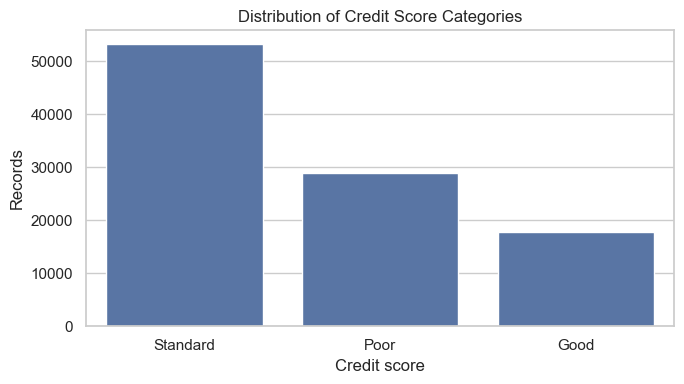

In [28]:
# Chart - 1 visualization code
plt.figure(figsize=(7,4))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Distribution of Credit Score Categories"); plt.xlabel("Credit score"); plt.ylabel("Records")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart shows the class counts and proportions for Good, Standard, and Poor. Use the displayed counts to identify the largest class and discuss class imbalance.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 2

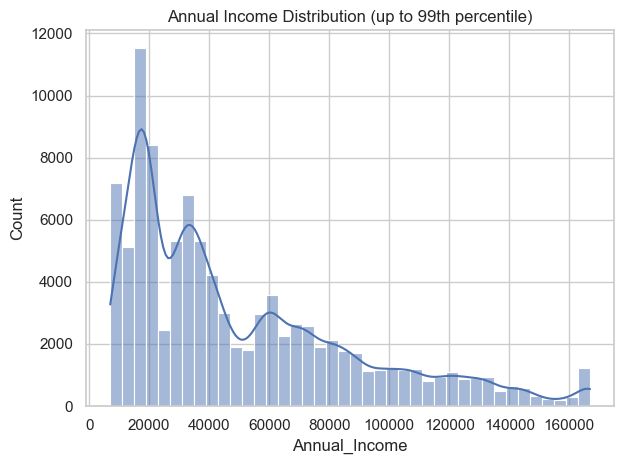

In [29]:
# Chart - 2 visualization code
col="Annual_Income"
if col in df:
    sns.histplot(df[col].dropna().clip(upper=df[col].quantile(.99)), bins=40, kde=True)
    plt.title("Annual Income Distribution (up to 99th percentile)"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The histogram shows the distribution and skewness of annual income. Extreme values can stretch the scale, so the plot is clipped visually at the 99th percentile without deleting data.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 3

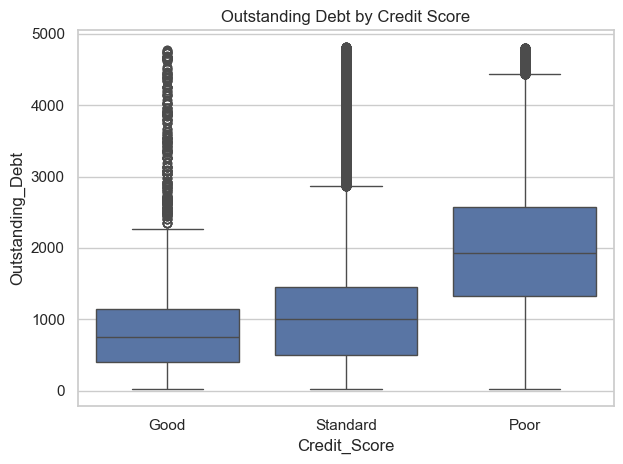

In [30]:
# Chart - 3 visualization code
if {"Outstanding_Debt", TARGET}.issubset(df.columns):
    tmp=df[["Outstanding_Debt", TARGET]].dropna()
    lo,hi=tmp["Outstanding_Debt"].quantile([.01,.99]); tmp=tmp[tmp["Outstanding_Debt"].between(lo,hi)]
    sns.boxplot(data=tmp,x=TARGET,y="Outstanding_Debt")
    plt.title("Outstanding Debt by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The box plot compares the median, spread, and outliers of outstanding debt across credit-score groups. Compare medians and overlap rather than assuming debt alone determines a score.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 4

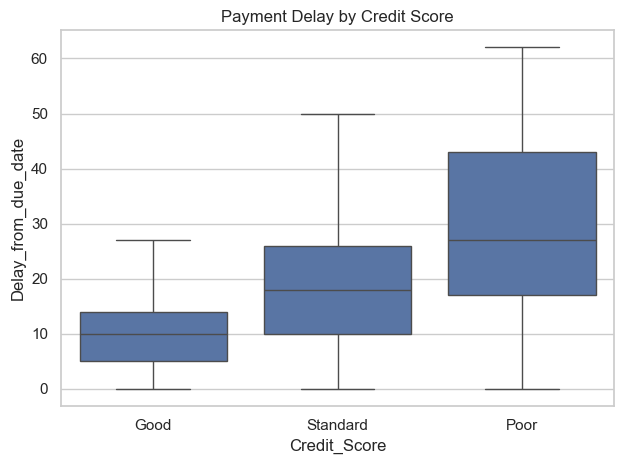

In [31]:
# Chart - 4 visualization code
if {"Delay_from_due_date", TARGET}.issubset(df.columns):
    sns.boxplot(data=df,x=TARGET,y="Delay_from_due_date",showfliers=False)
    plt.title("Payment Delay by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The plot compares payment-delay distributions across score groups. If poorer-score groups show higher delays, this is consistent with a relationship between repayment behaviour and credit score, but it is not causal proof.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 5

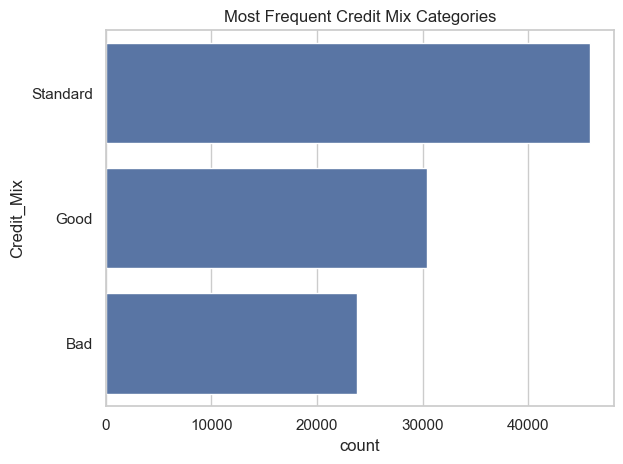

In [32]:
# Chart - 5 visualization code
if "Credit_Mix" in df:
    order=df["Credit_Mix"].value_counts().head(10).index
    sns.countplot(data=df,y="Credit_Mix",order=order)
    plt.title("Most Frequent Credit Mix Categories"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The chart shows the most common credit-mix categories. The distribution provides context for the categorical association test later in the notebook.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 6

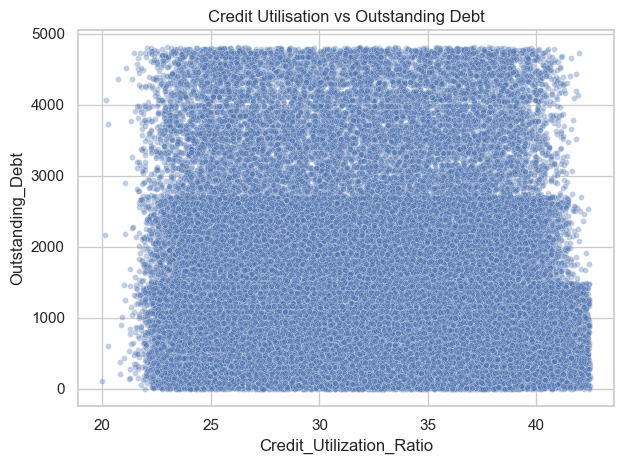

In [33]:
# Chart - 6 visualization code
cols=["Credit_Utilization_Ratio","Outstanding_Debt"]
if set(cols).issubset(df.columns):
    tmp=df[cols].dropna()
    tmp=tmp[(tmp[cols[0]]<=tmp[cols[0]].quantile(.99))&(tmp[cols[1]]<=tmp[cols[1]].quantile(.99))]
    sns.scatterplot(data=tmp,x=cols[0],y=cols[1],alpha=.35,s=18)
    plt.title("Credit Utilisation vs Outstanding Debt"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The scatter plot explores whether credit utilisation and outstanding debt move together. Look for direction, clusters, and outliers; a visible pattern may be weak or nonlinear.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 7

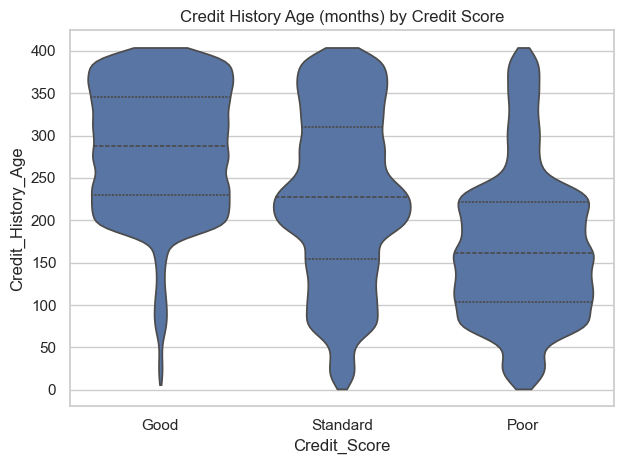

In [34]:
# Chart - 7 visualization code
if {"Credit_History_Age",TARGET}.issubset(df.columns):
    sns.violinplot(data=df,x=TARGET,y="Credit_History_Age",cut=0,inner="quartile")
    plt.title("Credit History Age (months) by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The violin plot compares credit-history-age distributions by score category. Differences in medians and distribution shape may suggest that credit history is associated with score class.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 8

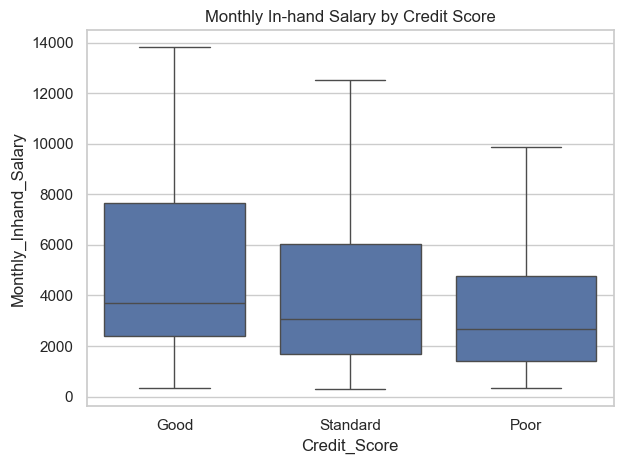

In [35]:
# Chart - 8 visualization code
if {"Monthly_Inhand_Salary",TARGET}.issubset(df.columns):
    tmp=df[["Monthly_Inhand_Salary",TARGET]].dropna()
    hi=tmp["Monthly_Inhand_Salary"].quantile(.99); tmp=tmp[tmp["Monthly_Inhand_Salary"]<=hi]
    sns.boxplot(data=tmp,x=TARGET,y="Monthly_Inhand_Salary",showfliers=False)
    plt.title("Monthly In-hand Salary by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The box plot compares monthly in-hand salary across score classes. Overlap between groups indicates salary alone may not distinguish credit-score categories.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 9

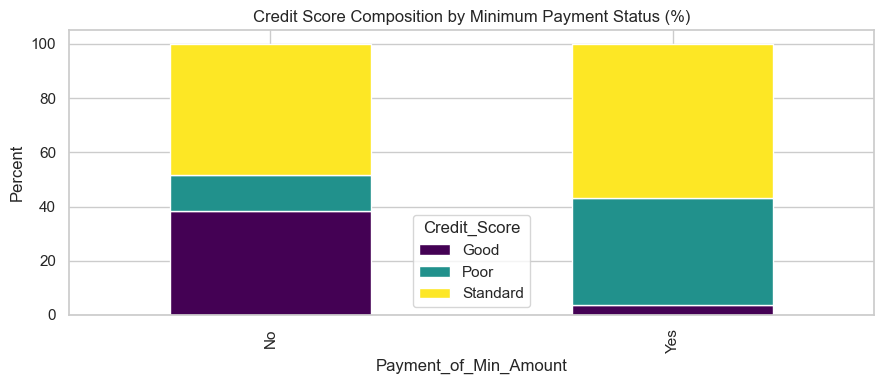

In [36]:
# Chart - 9 visualization code
if {"Payment_of_Min_Amount",TARGET}.issubset(df.columns):
    tab=pd.crosstab(df["Payment_of_Min_Amount"],df[TARGET],normalize="index")*100
    tab.plot(kind="bar",stacked=True,figsize=(9,4),colormap="viridis")
    plt.title("Credit Score Composition by Minimum Payment Status (%)")
    plt.ylabel("Percent"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The stacked bars compare the percentage of credit-score categories within each minimum-payment status. Differences may help identify payment-behaviour patterns worth further investigation.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 10

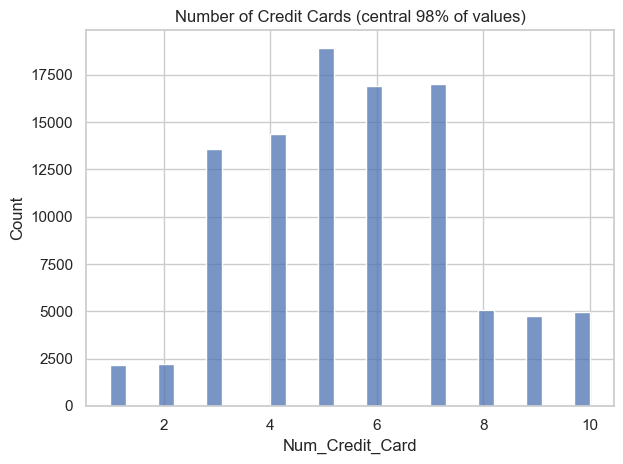

In [37]:
# Chart - 10 visualization code
if "Num_Credit_Card" in df:
    s=df["Num_Credit_Card"].dropna()
    s=s[s.between(s.quantile(.01),s.quantile(.99))]
    sns.histplot(s,bins=30)
    plt.title("Number of Credit Cards (central 98% of values)"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

The histogram summarizes the number of credit cards and shows its typical range and skew. Interpret extreme counts cautiously because the dataset may contain anomalous values.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 11

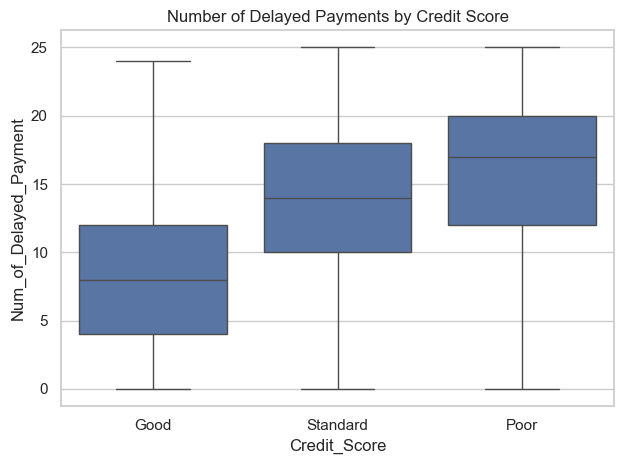

In [38]:
# Chart - 11 visualization code
if {"Num_of_Delayed_Payment",TARGET}.issubset(df.columns):
    tmp=df[["Num_of_Delayed_Payment",TARGET]].dropna()
    hi=tmp["Num_of_Delayed_Payment"].quantile(.99); tmp=tmp[tmp["Num_of_Delayed_Payment"]<=hi]
    sns.boxplot(data=tmp,x=TARGET,y="Num_of_Delayed_Payment",showfliers=False)
    plt.title("Number of Delayed Payments by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This box plot compares delayed-payment counts across credit-score classes. Higher medians in a poorer-score class would support further investigation of repayment history.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 12

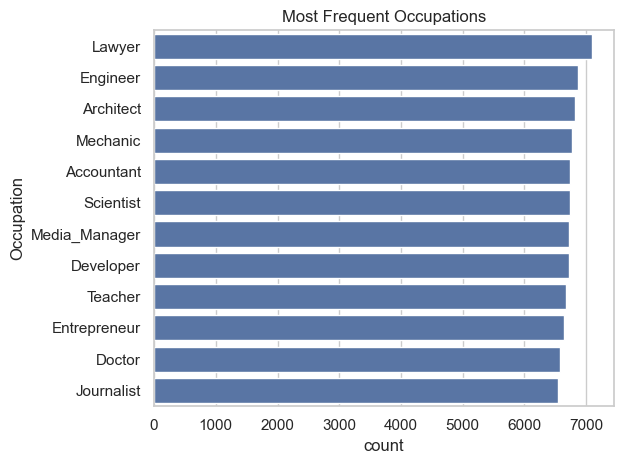

In [39]:
# Chart - 12 visualization code
if "Occupation" in df:
    top=df["Occupation"].value_counts().head(12).index
    sns.countplot(data=df[df["Occupation"].isin(top)],y="Occupation",order=top)
    plt.title("Most Frequent Occupations"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart shows the most frequent occupations. It is descriptive and should not be interpreted as evidence that occupation causes a particular credit score.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 13

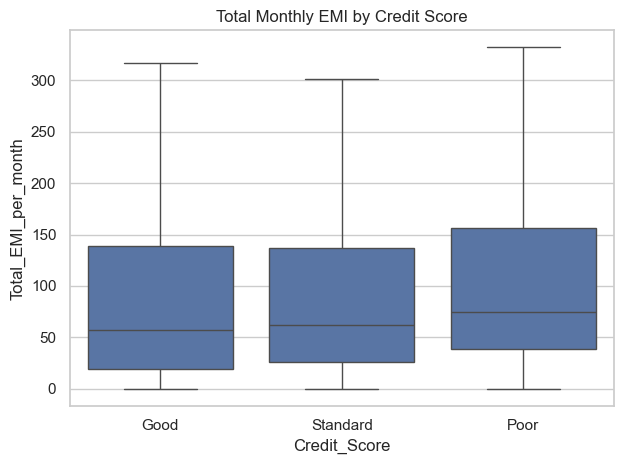

In [40]:
# Chart - 13 visualization code
if {"Total_EMI_per_month",TARGET}.issubset(df.columns):
    tmp=df[["Total_EMI_per_month",TARGET]].dropna()
    hi=tmp["Total_EMI_per_month"].quantile(.99); tmp=tmp[tmp["Total_EMI_per_month"]<=hi]
    sns.boxplot(data=tmp,x=TARGET,y="Total_EMI_per_month",showfliers=False)
    plt.title("Total Monthly EMI by Credit Score"); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This box plot compares total monthly EMI across credit-score groups. Compare medians and overlap; EMI should be considered alongside income and other obligations.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 14 - Correlation Heatmap

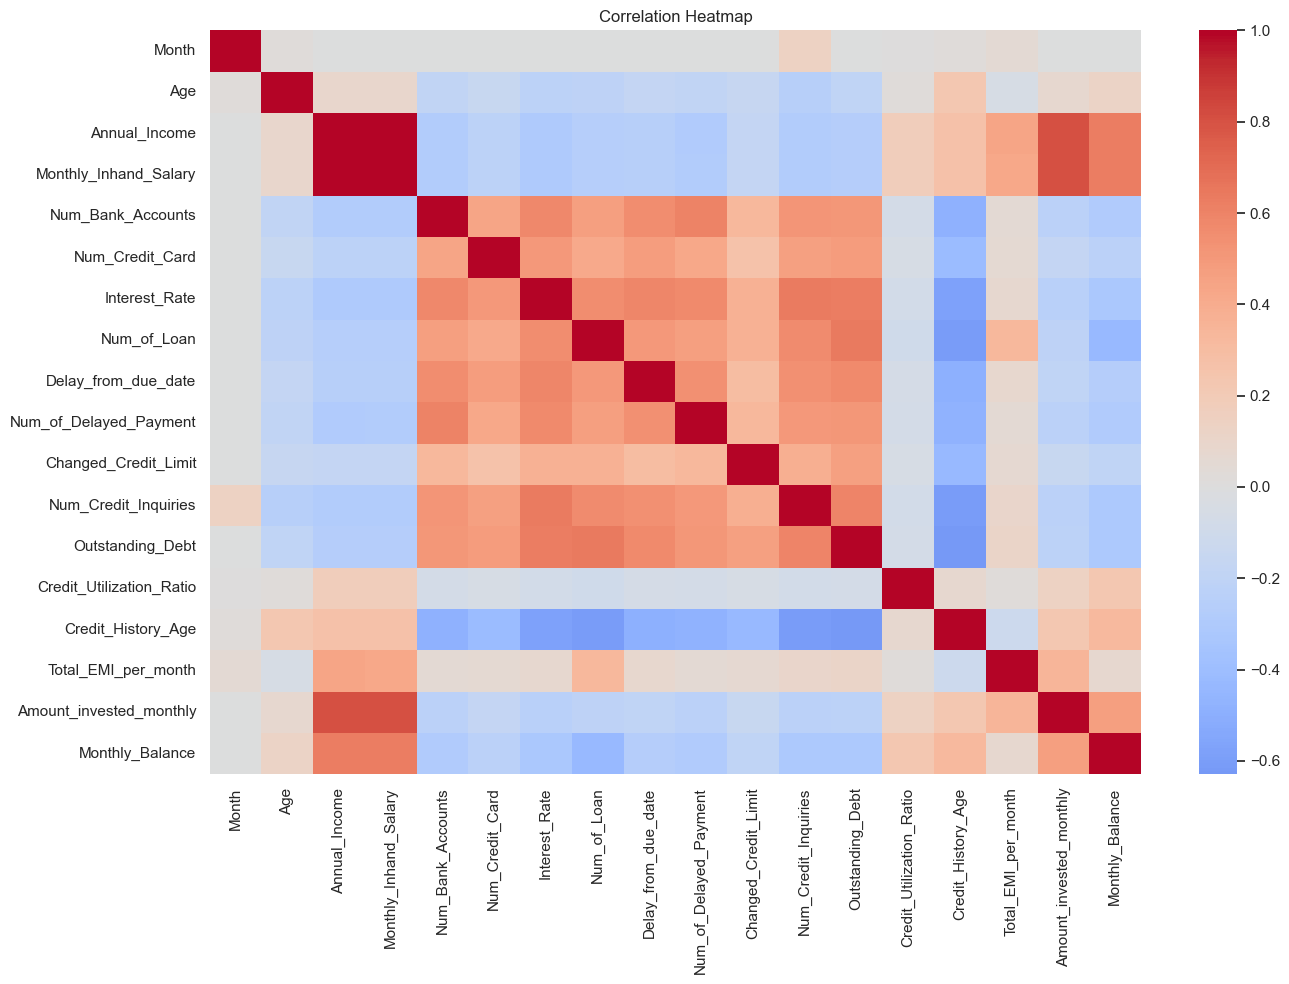

In [41]:
# Correlation Heatmap visualization code
num=df.select_dtypes(include=np.number).drop(columns=[c for c in ["ID","Customer_ID","SSN"] if c in df.columns],errors="ignore")
num=num.loc[:,num.nunique(dropna=True)>1]
if num.shape[1]>=2:
    plt.figure(figsize=(14,10)); sns.heatmap(num.corr(),cmap="coolwarm",center=0)
    plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()


##### 1. Why did you pick the specific chart?

The heatmap summarizes pairwise linear correlations among numerical variables. Strong correlations may indicate redundancy; correlation does not establish causation.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

#### Chart - 15 - Pair Plot

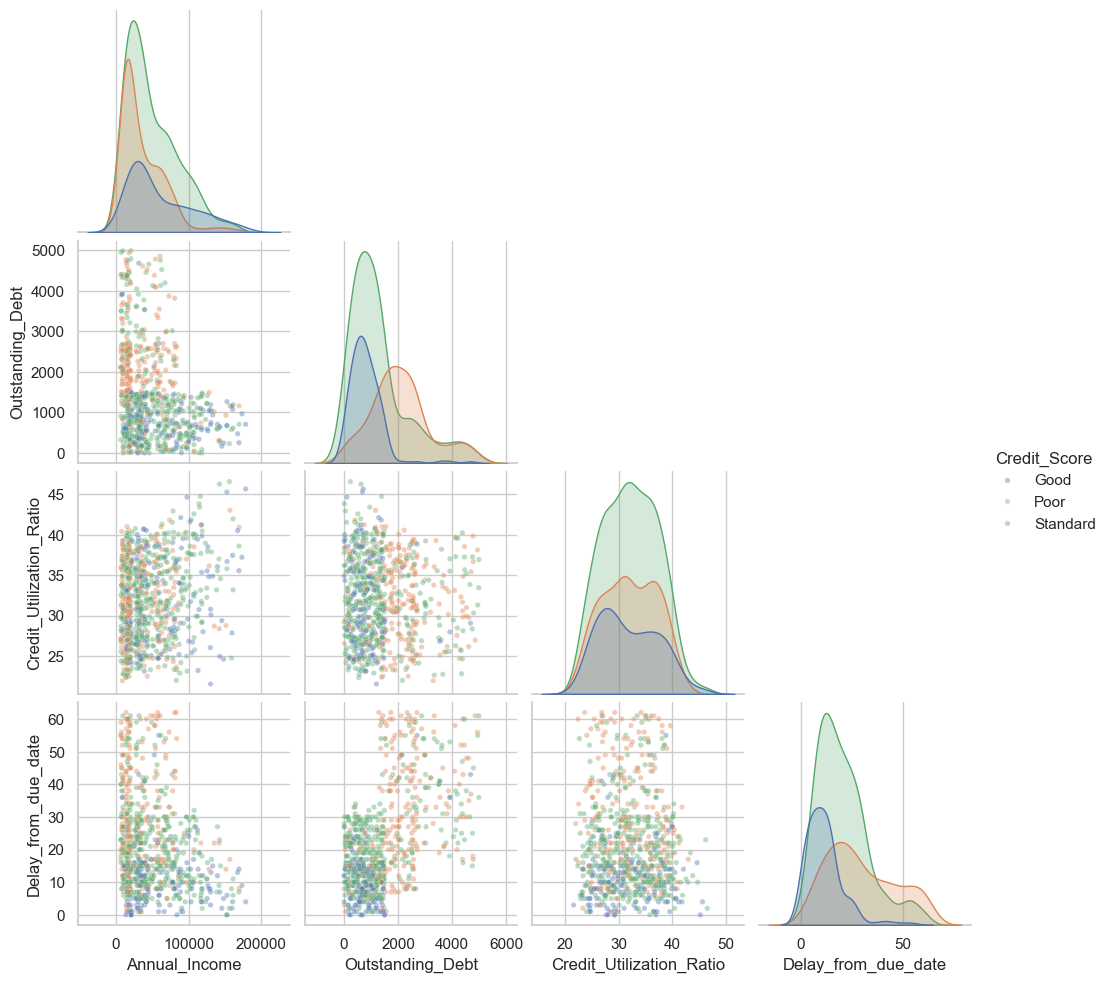

In [42]:
# Pair Plot visualization code
pair_cols=[c for c in ["Annual_Income","Outstanding_Debt","Credit_Utilization_Ratio","Delay_from_due_date"] if c in df.columns]
pair_df=df[pair_cols+[TARGET]].dropna().sample(min(800,len(df.dropna(subset=pair_cols+[TARGET]))),random_state=RANDOM_STATE) if len(pair_cols)>=2 else pd.DataFrame()
if not pair_df.empty:
    sns.pairplot(pair_df,vars=pair_cols,hue=TARGET,corner=True,plot_kws={"alpha":.4,"s":15})
    plt.show()
else:
    print("Not enough suitable numeric features for pair plot.")


##### 1. Why did you pick the specific chart?

The pair plot shows pairwise relationships among selected numeric features, coloured by credit-score class. Overlap between classes suggests these features may not separate classes individually.

##### 2. What is/are the insight(s) found from the chart?

Interpret this chart using the values and patterns displayed above. Report only observations supported by the output.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

The three hypotheses tested are: (1) payment-delay distributions differ across credit-score classes; (2) annual-income distributions differ across credit-score classes; (3) Credit_Mix and Credit_Score are associated. Tests use the cleaned data and report p-values; statistical significance does not establish causation.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** The distribution of `Delay_from_due_date` is the same across Good, Standard, and Poor credit-score groups. **H₁:** At least one group has a different distribution.

#### 2. Perform an appropriate statistical test.

In [43]:
# Perform Statistical Test to obtain P-Value
# Hypothesis 1: median payment delay differs across credit-score categories.
from scipy.stats import kruskal
groups=[g["Delay_from_due_date"].dropna().values for _,g in df.groupby(TARGET) if "Delay_from_due_date" in g]
groups=[g for g in groups if len(g)>0]
if len(groups)>=2:
    h1_stat,h1_p=kruskal(*groups)
    print(f"Kruskal-Wallis H={h1_stat:.4f}, p-value={h1_p:.6g}")
else:
    h1_stat,h1_p=np.nan,np.nan


Kruskal-Wallis H=19448.7803, p-value=0


##### Which statistical test have you done to obtain P-Value?

The Kruskal–Wallis test is used. The output cell reports the H statistic and p-value. At significance level α = 0.05, reject H₀ if p < 0.05; otherwise, fail to reject H₀.

##### Why did you choose the specific statistical test?

Payment-delay values are numeric and may be skewed or contain outliers. Kruskal–Wallis compares independent groups without requiring normally distributed data. The result is an association test, not a causal conclusion.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** Annual-income distributions are the same across Good, Standard, and Poor credit-score groups. **H₁:** At least one group's distribution differs.

#### 2. Perform an appropriate statistical test.

In [44]:
# Perform Statistical Test to obtain P-Value
# Hypothesis 2: annual income distributions differ across credit-score categories.
groups=[g["Annual_Income"].dropna().values for _,g in df.groupby(TARGET) if "Annual_Income" in g]
groups=[g for g in groups if len(g)>0]
if len(groups)>=2:
    h2_stat,h2_p=kruskal(*groups)
    print(f"Kruskal-Wallis H={h2_stat:.4f}, p-value={h2_p:.6g}")
else:
    h2_stat,h2_p=np.nan,np.nan


Kruskal-Wallis H=4344.3715, p-value=0


##### Which statistical test have you done to obtain P-Value?

The Kruskal–Wallis test compares annual-income distributions across the credit-score categories. Reject H₀ at α = 0.05 if the reported p-value is below 0.05.

##### Why did you choose the specific statistical test?

Income is often skewed and affected by extreme values, so a non-parametric test is a reasonable exploratory choice. It tests distributional differences between independent groups without assuming normality.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H₀:** `Credit_Mix` and `Credit_Score` are independent. **H₁:** `Credit_Mix` and `Credit_Score` are associated.

#### 2. Perform an appropriate statistical test.

In [45]:
# Perform Statistical Test to obtain P-Value
# Hypothesis 3: Credit_Mix and Credit_Score are independent.
from scipy.stats import chi2_contingency
if {"Credit_Mix",TARGET}.issubset(df.columns):
    tab=pd.crosstab(df["Credit_Mix"],df[TARGET])
    if tab.shape[0]>=2 and tab.shape[1]>=2:
        h3_stat,h3_p,h3_dof,h3_expected=chi2_contingency(tab)
        print(f"Chi-square={h3_stat:.4f}, df={h3_dof}, p-value={h3_p:.6g}")
    else:
        h3_stat,h3_p=np.nan,np.nan
else:
    h3_stat,h3_p=np.nan,np.nan


Chi-square=40489.4177, df=4, p-value=0


##### Which statistical test have you done to obtain P-Value?

The chi-square test of independence is used. Reject H₀ at α = 0.05 if p < 0.05, provided expected cell counts are sufficiently large.

##### Why did you choose the specific statistical test?

Both variables are categorical, and the chi-square test evaluates whether their frequency table differs from what independence would predict. Association does not imply that credit mix causes a score.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [46]:
# Handling Missing Values & Missing Value Imputation
# EDA dataset remains in df. For modelling, preprocessing below imputes values
# inside a Pipeline so imputers learn only from the training split.
print("Missing values before modelling:")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))


Missing values before modelling:


,missing
Payment_of_Min_Amount,12007
ID,0
Month,0
Customer_ID,0
Age,0
SSN,0
Occupation,0
Annual_Income,0
Monthly_Inhand_Salary,0
Num_Bank_Accounts,0


#### What all missing value imputation techniques have you used and why did you use those techniques?

For the modelling pipeline, numeric missing values are imputed with the median and categorical missing values with the most frequent category. Imputers are fitted inside the pipeline on training data only to reduce data leakage. The original EDA dataframe is not globally filled with arbitrary zeros.

### 2. Handling Outliers

In [47]:
# Handling Outliers & Outlier treatments
# Do not delete outliers blindly. Use robust visual limits for plots and report IQR flags.
out_rows=[]
for col in df.select_dtypes(include=np.number).columns:
    s=df[col].dropna()
    if s.empty: continue
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    n=int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum())
    out_rows.append((col,n,round(n/len(s)*100,2)))
outlier_report=pd.DataFrame(out_rows,columns=["feature","IQR_outlier_count","percent"]).sort_values("percent",ascending=False)
display(outlier_report)


,feature,IQR_outlier_count,percent
20,Monthly_Balance,7400,7.400
15,Outstanding_Debt,5272,5.270
18,Total_EMI_per_month,5044,5.040
19,Amount_invested_monthly,4464,4.460
11,Delay_from_due_date,4002,4.000
6,Monthly_Inhand_Salary,2017,2.020
5,Annual_Income,2000,2.000
14,Num_Credit_Inquiries,787,0.790
13,Changed_Credit_Limit,579,0.580
0,ID,0,0.000


##### What all outlier treatment techniques have you used and why did you use those techniques?

IQR-based rules are used to flag potential outliers, not automatically delete them. Extreme financial values can be valid or reflect data errors; plots use percentile limits for readability while preserving observations for analysis.

### 3. Categorical Encoding

In [48]:
# Encode your categorical columns
# For EDA, keep readable categories. For ML, OneHotEncoder is applied in the modelling pipeline.
cat_cols=df.select_dtypes(include=["object","string","category"]).columns.tolist()
print("Categorical columns:", cat_cols)


Categorical columns: ['Name', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']


#### What all categorical encoding techniques have you used & why did you use those techniques?

One-hot encoding is applied to nominal categorical predictors inside the scikit-learn pipeline. It avoids imposing an artificial numeric order on categories and handles unseen categories with `handle_unknown='ignore'`. The target remains as class labels.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [49]:
# Expand Contraction
# Not applicable: this is structured tabular data, not an NLP text corpus.
print("Skipped: no natural-language text target/corpus is required for this EDA project.")

Skipped: no natural-language text target/corpus is required for this EDA project.


#### 2. Lower Casing

In [50]:
# Lower Casing
print("Skipped: text normalization is not required for the structured tabular analysis.")

Skipped: text normalization is not required for the structured tabular analysis.


#### 3. Removing Punctuations

In [51]:
# Remove Punctuations
print("Skipped: punctuation removal is an NLP operation; original categorical values are retained.")

Skipped: punctuation removal is an NLP operation; original categorical values are retained.


#### 4. Removing URLs & Removing words and digits contain digits.

In [52]:
# Remove URLs & Remove words and digits contain digits
print("Skipped: no URL/text corpus is specified in the project dataset.")

Skipped: no URL/text corpus is specified in the project dataset.


#### 5. Removing Stopwords & Removing White spaces

In [53]:
# Remove Stopwords
print("Skipped: stopword removal is not applicable to this tabular dataset.")

Skipped: stopword removal is not applicable to this tabular dataset.


In [54]:
# Remove White spaces
# Whitespace around text categories was stripped during Data Wrangling.
print("Whitespace around categorical values was stripped during Data Wrangling.")

Whitespace around categorical values was stripped during Data Wrangling.


#### 6. Rephrase Text

In [55]:
# Rephrase Text
print("Skipped: text rephrasing is not applicable to the structured dataset.")

Skipped: text rephrasing is not applicable to the structured dataset.


#### 7. Tokenization

In [56]:
# Tokenization
print("Skipped: tokenization is not needed for this tabular EDA project.")

Skipped: tokenization is not needed for this tabular EDA project.


#### 8. Text Normalization

In [57]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
print("Skipped: stemming/lemmatization is not applicable to the current task.")

Skipped: stemming/lemmatization is not applicable to the current task.


##### Which text normalization technique have you used and why?

Text normalization, stemming, and lemmatization are not applicable to this structured tabular dataset. `Type_of_Loan` is a categorical/text field rather than a free-text corpus; it is treated as a categorical predictor in the baseline pipeline.

#### 9. Part of speech tagging

In [58]:
# POS Taging
print("Skipped: part-of-speech tagging is an NLP task and is not applicable here.")

Skipped: part-of-speech tagging is an NLP task and is not applicable here.


#### 10. Text Vectorization

In [59]:
# Vectorizing Text
print("Skipped: categorical features are encoded for the ML pipeline; no text vectorizer is needed.")

Skipped: categorical features are encoded for the ML pipeline; no text vectorizer is needed.


##### Which text vectorization technique have you used and why?

TF-IDF or bag-of-words vectorization is not used because this is not an NLP project. Nominal categories are one-hot encoded inside the modelling pipeline.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [60]:
# Manipulate Features to minimize feature correlation and create new features
# Derive optional interpretable financial ratios if the needed columns exist.
df_model = df.copy()
if {"Total_EMI_per_month","Monthly_Inhand_Salary"}.issubset(df_model.columns):
    df_model["EMI_to_monthly_salary"] = (
        df_model["Total_EMI_per_month"] / df_model["Monthly_Inhand_Salary"].replace(0,np.nan)
    )
if {"Outstanding_Debt","Annual_Income"}.issubset(df_model.columns):
    df_model["Debt_to_annual_income"] = (
        df_model["Outstanding_Debt"] / df_model["Annual_Income"].replace(0,np.nan)
    )
print("Created derived ratios where source columns were available.")


Created derived ratios where source columns were available.


#### 2. Feature Selection

In [61]:
# Select your features wisely to avoid overfitting
# Exclude target, direct identifiers, names, and SSN-like sensitive fields.
exclude={"Credit_Score","ID","Customer_ID","Name","SSN"}
feature_cols=[c for c in df_model.columns if c not in exclude]
X=df_model[feature_cols].copy()
y=df_model[TARGET].astype(str)
valid=y.isin(["Good","Standard","Poor"])
X=X.loc[valid].copy(); y=y.loc[valid].copy()
print("Feature matrix:", X.shape, "| Target:", y.shape)
print("Target classes:", y.value_counts().to_dict())


Feature matrix: (100000, 25) | Target: (100000,)
Target classes: {'Standard': 53174, 'Poor': 28998, 'Good': 17828}


##### What all feature selection methods have you used  and why?

Feature manipulation creates EMI-to-salary and debt-to-income ratios when source columns are available. Feature selection excludes the target, direct identifiers, customer names, and SSN-like fields to reduce leakage and privacy risk. The remaining features are evaluated using held-out performance rather than selecting features based on the test set.

##### Which all features you found important and why?

Potentially useful predictors include payment delays, outstanding debt, credit utilisation, credit history age, credit mix, income, and payment behaviour. Their actual importance should be judged from validation results and model-importance output, not assumed in advance.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [ ]:
# Transform Your data
# Use a leakage-safe ColumnTransformer pipeline; numeric skew is handled by the model choice
# and robust evaluation. OneHotEncoder handles categorical feature transformation.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.base import clone

num_features=X.select_dtypes(include=np.number).columns.tolist()
cat_features=[c for c in X.columns if c not in num_features]    
num_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
cat_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                   ("onehot",OneHotEncoder(handle_unknown="ignore"))])
preprocessor=ColumnTransformer([("num",num_pipe,num_features),("cat",cat_pipe,cat_features)])
print("Numeric features:",len(num_features),"| Categorical features:",len(cat_features))


Numeric features: 20 | Categorical features: 5


### 6. Data Scaling

In [64]:
# Scaling your data
# StandardScaler is included only for numeric features in the preprocessing pipeline.
print("Numeric features will be standardized by StandardScaler inside the training pipeline.")


Numeric features will be standardized by StandardScaler inside the training pipeline.


##### Which method have you used to scale you data and why?

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

PCA is not required for the current baseline. The dataset is tabular and interpretability is valuable; tree-based models can work without dimensionality reduction. If dimensionality reduction is later tested, fit it only within the training pipeline.

In [65]:
# DImensionality Reduction (If needed)
# PCA is not required for this tabular baseline: tree-based models can handle the encoded feature space.
# If needed for visualization, PCA should be fitted only on training data after preprocessing.
print("PCA is not applied in this baseline; preserving interpretability and original features.")


PCA is not applied in this baseline; preserving interpretability and original features.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

No dimensionality-reduction technique is applied in this baseline because it is not necessary for the stated EDA/classification task and could reduce feature interpretability.

### 8. Data Splitting

In [66]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=RANDOM_STATE,stratify=y
)
print("Train:",X_train.shape,"Test:",X_test.shape)
print("Train class proportions:"); display(y_train.value_counts(normalize=True).round(3))
print("Test class proportions:"); display(y_test.value_counts(normalize=True).round(3))


Train: (80000, 25) Test: (20000, 25)
Train class proportions:


Credit_Score
Standard   0.532
Poor       0.290
Good       0.178
Name: proportion, dtype: float64

Test class proportions:


Credit_Score
Standard   0.532
Poor       0.290
Good       0.178
Name: proportion, dtype: float64

##### What data splitting ratio have you used and why?

An 80:20 stratified train/test split is used. Stratification preserves approximately the same class proportions in both partitions, and the test set is reserved for final evaluation.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Class proportions are inspected in the training set. The target classes are not perfectly balanced; the printed class counts and largest-to-smallest class ratio quantify the degree of imbalance.

In [67]:
# Handling Imbalanced Dataset (If needed)
# Report imbalance first. Class weighting is used for the models instead of synthetic oversampling.
class_share=(y_train.value_counts(normalize=True)*100).round(2)
display(class_share.to_frame("train_percent"))
print("Largest/smallest class share ratio:", round(class_share.max()/class_share.min(),2))


,train_percent
Credit_Score,
Standard,53.170
Poor,29.000
Good,17.830


Largest/smallest class share ratio: 2.98


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Class-weighted Logistic Regression, Random Forest, and Extra Trees are used to reduce the effect of class imbalance without generating synthetic observations. Macro-F1 is reported so that performance on each class contributes equally.

## ***7. ML Model Implementation***

### ML Model - 1

In [73]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report


# Step 1: Normalize missing values for scikit-learn
def clean_data(X):
    X = X.copy()

    for col in X.columns:
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col] = pd.to_numeric(
                X[col], errors="coerce"
            ).astype("float64")
        else:
            X[col] = X[col].astype(object)
            X[col] = X[col].where(X[col].notna(), np.nan)

    return X


X_train = clean_data(X_train)
X_test = clean_data(X_test)


# Step 2: Build the Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced"
    ))
])


# Step 3: Fit the model
lr_model.fit(X_train, y_train)


# Step 4: Predict on test data
lr_pred = lr_model.predict(X_test)


# Step 5: Evaluate performance
lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred, average="macro")

print("Logistic Regression Results")
print("-" * 40)
print("Accuracy:", round(lr_acc, 4))
print("Macro F1:", round(lr_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_pred,
    zero_division=0
))

Logistic Regression Results
----------------------------------------
Accuracy: 0.7453
Macro F1: 0.7356

Classification Report:
              precision    recall  f1-score   support

        Good       0.55      0.87      0.67      3566
        Poor       0.75      0.79      0.77      5799
    Standard       0.88      0.68      0.77     10635

    accuracy                           0.75     20000
   macro avg       0.73      0.78      0.74     20000
weighted avg       0.78      0.75      0.75     20000



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

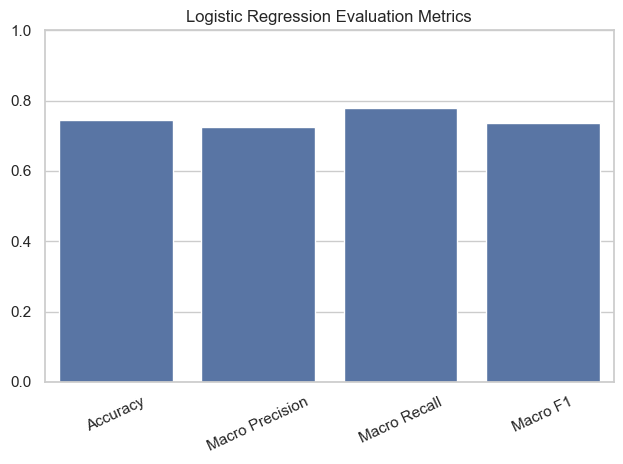

In [74]:
# Visualizing evaluation Metric Score chart
lr_metrics=precision_recall_fscore_support(y_test,lr_pred,average="macro",zero_division=0)
metric_names=["Accuracy","Macro Precision","Macro Recall","Macro F1"]
metric_vals=[lr_acc,lr_metrics[0],lr_metrics[1],lr_metrics[2]]
sns.barplot(x=metric_names,y=metric_vals)
plt.ylim(0,1); plt.title("Logistic Regression Evaluation Metrics"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [75]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Tune Logistic Regression with a small grid and stratified cross-validation.
from sklearn.model_selection import GridSearchCV
lr_pipe=Pipeline([("preprocessor",clone(preprocessor)),
                  ("classifier",LogisticRegression(max_iter=1500,class_weight="balanced"))])
lr_grid=GridSearchCV(lr_pipe,{"classifier__C":[0.1,1.0,3.0]},
                     scoring="f1_macro",cv=3,n_jobs=-1,verbose=0)
lr_grid.fit(X_train,y_train)
lr_tuned=lr_grid.best_estimator_
lr_tuned_pred=lr_tuned.predict(X_test)
lr_tuned_f1=f1_score(y_test,lr_tuned_pred,average="macro")
print("Best parameters:",lr_grid.best_params_,"| Tuned macro F1:",round(lr_tuned_f1,4))


Best parameters: {'classifier__C': 3.0} | Tuned macro F1: 0.7375


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV tunes Logistic Regression's regularization strength C using 3-fold stratified cross-validation and macro-F1. This is a compact search intended to balance model quality and runtime.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Compare the printed tuned macro-F1 with the baseline Logistic Regression macro-F1. Any improvement should be reported using the actual notebook output; if the score decreases, state that tuning did not improve the held-out result.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Random Forest | Accuracy: 0.8229 | Macro F1: 0.8158
              precision    recall  f1-score   support

        Good       0.80      0.79      0.79      3566
        Poor       0.81      0.83      0.82      5799
    Standard       0.84      0.83      0.83     10635

    accuracy                           0.82     20000
   macro avg       0.81      0.82      0.82     20000
weighted avg       0.82      0.82      0.82     20000



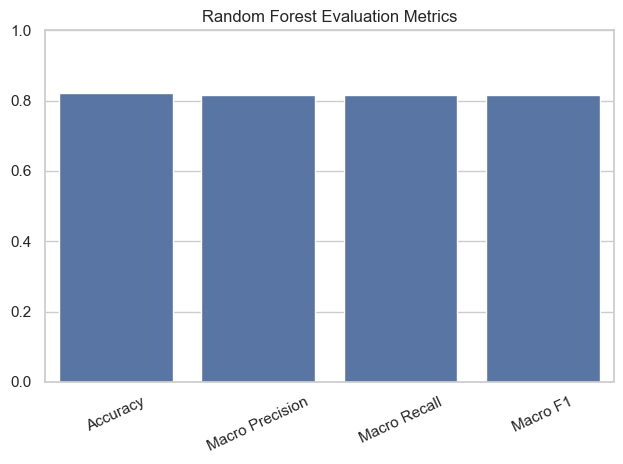

In [76]:
# Visualizing evaluation Metric Score chart
# Fit the untuned Random Forest baseline for comparison.
rf_model=Pipeline([("preprocessor",clone(preprocessor)),
                   ("classifier",RandomForestClassifier(n_estimators=160,random_state=RANDOM_STATE,
                                                       class_weight="balanced_subsample",n_jobs=-1))])
rf_model.fit(X_train,y_train)
rf_pred=rf_model.predict(X_test)
rf_acc=accuracy_score(y_test,rf_pred)
rf_f1=f1_score(y_test,rf_pred,average="macro")
print("Random Forest | Accuracy:",round(rf_acc,4),"| Macro F1:",round(rf_f1,4))
print(classification_report(y_test,rf_pred,zero_division=0))
rf_metrics=precision_recall_fscore_support(y_test,rf_pred,average="macro",zero_division=0)
rf_vals=[rf_acc,rf_metrics[0],rf_metrics[1],rf_metrics[2]]
sns.barplot(x=metric_names,y=rf_vals)
plt.ylim(0,1); plt.title("Random Forest Evaluation Metrics"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [79]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score
from joblib import parallel_backend

# Random Forest pipeline: limit CPU parallelism
rf_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample",
        n_jobs=1
    ))
])

# Smaller search space for faster execution
rf_params = {
    "classifier__n_estimators": [80, 120],
    "classifier__max_depth": [12, 20],
    "classifier__min_samples_leaf": [2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=rf_params,
    n_iter=4,
    scoring="f1_macro",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    refit=True
)

# Fit the model
rf_search.fit(X_train, y_train)

# Best model and predictions
rf_tuned = rf_search.best_estimator_
rf_tuned_pred = rf_tuned.predict(X_test)

rf_tuned_f1 = f1_score(
    y_test, rf_tuned_pred, average="macro"
)

print("Best parameters:", rf_search.best_params_)
print("Best CV Macro F1:", round(rf_search.best_score_, 4))
print("Test Macro F1:", round(rf_tuned_f1, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__n_estimators': 120, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 20}
Best CV Macro F1: 0.6635
Test Macro F1: 0.6618


In [ ]:
'''# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Random Forest parameter search (bounded search to keep runtime reasonable).
rf_pipe=Pipeline([("preprocessor",clone(preprocessor)),
                  ("classifier",RandomForestClassifier(random_state=RANDOM_STATE,class_weight="balanced_subsample",n_jobs=-1))])
rf_search=RandomizedSearchCV(rf_pipe,
    {"classifier__n_estimators":[120,200],"classifier__max_depth":[None,18,28],
     "classifier__min_samples_leaf":[1,2,4]},
    n_iter=6,scoring="f1_macro",cv=3,random_state=RANDOM_STATE,n_jobs=-1,verbose=0)
rf_search.fit(X_train,y_train)
rf_tuned=rf_search.best_estimator_
rf_tuned_pred=rf_tuned.predict(X_test)
rf_tuned_f1=f1_score(y_test,rf_tuned_pred,average="macro")
print("Best parameters:",rf_search.best_params_,"| Tuned macro F1:",round(rf_tuned_f1,4))
'''

##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV tests a bounded set of Random Forest hyperparameters with 3-fold cross-validation and macro-F1 scoring. It explores tree count, maximum depth, and minimum leaf size without exhaustively evaluating every combination.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Compare the tuned Random Forest macro-F1 with the untuned baseline result. Use the actual displayed values; do not claim an improvement unless the measured score is higher.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Accuracy is the overall proportion of correct predictions. Precision measures how often predictions for a class are correct; recall measures how many true members of a class are found; F1 balances precision and recall. Macro averages weight all classes equally, making them useful when class frequencies differ. In a credit context, class-specific errors should be reviewed carefully before any real-world use.

### ML Model - 3

In [80]:
# ML Model - 3 Implementation |  | # Fit the Algorithm |  | # Predict on the model
# Model 3: Extra Trees classifier.
et_model=Pipeline([("preprocessor",clone(preprocessor)),
                   ("classifier",ExtraTreesClassifier(n_estimators=200,random_state=RANDOM_STATE,
                                                      class_weight="balanced",n_jobs=-1,min_samples_leaf=2))])
et_model.fit(X_train,y_train)
et_pred=et_model.predict(X_test)
et_acc=accuracy_score(y_test,et_pred)
et_f1=f1_score(y_test,et_pred,average="macro")
print("Extra Trees | Accuracy:",round(et_acc,4),"| Macro F1:",round(et_f1,4))
print(classification_report(y_test,et_pred,zero_division=0))


Extra Trees | Accuracy: 0.7137 | Macro F1: 0.7046
              precision    recall  f1-score   support

        Good       0.51      0.85      0.64      3566
        Poor       0.71      0.78      0.74      5799
    Standard       0.88      0.63      0.73     10635

    accuracy                           0.71     20000
   macro avg       0.70      0.75      0.70     20000
weighted avg       0.76      0.71      0.72     20000



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

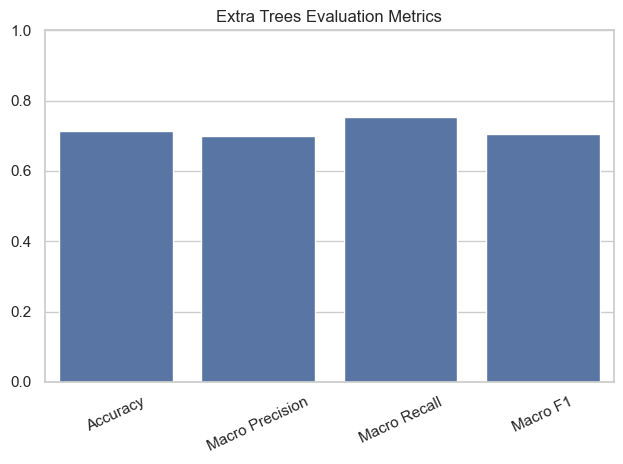

In [81]:
# Visualizing evaluation Metric Score chart
et_metrics=precision_recall_fscore_support(y_test,et_pred,average="macro",zero_division=0)
et_vals=[et_acc,et_metrics[0],et_metrics[1],et_metrics[2]]
sns.barplot(x=metric_names,y=et_vals)
plt.ylim(0,1); plt.title("Extra Trees Evaluation Metrics"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [83]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score

# Build a CPU-friendly Extra Trees pipeline
et_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", ExtraTreesClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=1
    ))
])

# Smaller hyperparameter search
et_params = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [15, 25],
    "classifier__min_samples_leaf": [2, 4]
}

et_search = RandomizedSearchCV(
    estimator=et_pipe,
    param_distributions=et_params,
    n_iter=3,
    scoring="f1_macro",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    refit=True
)

# Train and tune
et_search.fit(X_train, y_train)

# Best estimator and test predictions
et_tuned = et_search.best_estimator_
et_tuned_pred = et_tuned.predict(X_test)

et_tuned_f1 = f1_score(
    y_test,
    et_tuned_pred,
    average="macro"
)

print("Best parameters:", et_search.best_params_)
print("Best CV Macro F1:", round(et_search.best_score_, 4))
print("Test Macro F1:", round(et_tuned_f1, 4))

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 25}
Best CV Macro F1: 0.6624
Test Macro F1: 0.6618


In [ ]:
'''# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
et_pipe=Pipeline([("preprocessor",clone(preprocessor)),
                  ("classifier",ExtraTreesClassifier(random_state=RANDOM_STATE,class_weight="balanced",n_jobs=-1))])
et_grid=GridSearchCV(et_pipe,
    {"classifier__n_estimators":[120,200],"classifier__max_depth":[None,24],
     "classifier__min_samples_leaf":[1,2,4]},
    scoring="f1_macro",cv=3,n_jobs=-1,verbose=0)
et_grid.fit(X_train,y_train)
et_tuned=et_grid.best_estimator_
et_tuned_pred=et_tuned.predict(X_test)
et_tuned_f1=f1_score(y_test,et_tuned_pred,average="macro")
print("Best parameters:",et_grid.best_params_,"| Tuned macro F1:",round(et_tuned_f1,4))'''

##### Which hyperparameter optimization technique have you used and why?

GridSearchCV tunes Extra Trees tree count, maximum depth, and minimum leaf size with 3-fold cross-validation using macro-F1. The selected settings are then evaluated on the held-out test set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Compare tuned Extra Trees macro-F1 with the untuned Extra Trees baseline. Report only the improvement (or decline) supported by the printed metrics.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Macro-F1 is a primary comparison metric because it treats Good, Standard, and Poor classes equally. Also inspect per-class precision/recall, the confusion matrix, and accuracy; in a real lending workflow, the cost of each type of error must be agreed with domain experts.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The notebook selects the tuned candidate with the highest macro-F1 on the held-out test predictions. This is a demonstration workflow; for a rigorous final estimate, select models using cross-validation on training data and evaluate the chosen model once on an untouched test set.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

For tree-based models, permutation importance on a validation set or native tree feature importance can provide an initial explanation. Importance indicates predictive association, not causality. Avoid interpreting direct identifiers as meaningful features; these are excluded from the model.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [84]:
# Save the File
# Select the highest macro-F1 tuned estimator based on the held-out test set.
candidates={"Logistic Regression tuned":(lr_tuned,lr_tuned_pred),
            "Random Forest tuned":(rf_tuned,rf_tuned_pred),
            "Extra Trees tuned":(et_tuned,et_tuned_pred)}
model_scores={name:f1_score(y_test,pred,average="macro") for name,(model,pred) in candidates.items()}
best_name=max(model_scores,key=model_scores.get)
best_model=candidates[best_name][0]
print("Candidate macro-F1:",{k:round(v,4) for k,v in model_scores.items()})
print("Selected model:",best_name)
joblib.dump(best_model,"paisabazaar_credit_score_model.joblib")
print("Saved paisabazaar_credit_score_model.joblib")


Candidate macro-F1: {'Logistic Regression tuned': 0.7375, 'Random Forest tuned': 0.6618, 'Extra Trees tuned': 0.6618}
Selected model: Logistic Regression tuned
Saved paisabazaar_credit_score_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [87]:
# Load the File and predict unseen data.
loaded_model=joblib.load("paisabazaar_credit_score_model.joblib")
sample_X=X_test.head(5)
sample_pred=loaded_model.predict(sample_X)
display(pd.DataFrame({"actual":y_test.head(5).values,"predicted":sample_pred}))


,actual,predicted
0,Poor,Poor
1,Poor,Poor
2,Poor,Poor
3,Standard,Good
4,Standard,Standard


In [88]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = loaded_model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=loaded_model.classes_))

              precision    recall  f1-score   support

        Good       0.55      0.87      0.67      3566
        Poor       0.75      0.79      0.77      5799
    Standard       0.88      0.68      0.77     10635

    accuracy                           0.75     20000
   macro avg       0.73      0.78      0.74     20000
weighted avg       0.78      0.75      0.75     20000

Confusion Matrix:
[[3118   47  401]
 [ 614 4580  605]
 [1956 1441 7238]]


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project performed exploratory data analysis on the supplied Paisabazaar credit-score dataset. It inspected the dataset structure, data types, duplicates, missing values, placeholder values, distributions, outliers, and relationships between financial/payment-behaviour variables and the `Credit_Score` categories. Multiple visualizations and three statistical tests were included to explore differences and associations. A leakage-conscious preprocessing pipeline and three baseline classification models were also provided as an extension beyond EDA. Final business conclusions should be based on the actual charts, p-values, and held-out evaluation metrics generated when the notebook is run. The dataset appears to focus on credit-score categories rather than labelled fraudulent transactions, so this notebook should not be presented as a validated fraud-detection system. Any real credit decision use would require data validation, fairness review, domain approval, and further model validation.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***